## 1. 프로젝트 개요 
- 프로젝트명: 
    **불량 선별 실적 시계열 분석**
    (Defect-Sorting-Performance-Analysis)
- 분석 기간: 2025년 8월 ~ 2026년 3월
- 분석 목적: 선별 실적에서 유의미한 추이 및 패턴을 도출한다.
- 분석 질문:
 1) 시간에 따른 처리 실적은 어떻게 변화하는가?
 2) 품종에 따른 실적의 변화에 패턴이 있는가?
 3) 처리 대상인 불량유형 구성비의 변화가 있는가? 

## 2. 기본 설정 및 원본 파일 내용 확인

- 기본 라이브러리 import, 그래프 크기/스타일을 미리 설정한다. 
- 원본 엑셀 파일을 불러와 데이터 구조를 확인한다.
- 시트 목록과 각 시트의 데이터 내용을 확인한다.  
- 표를 구성하는 칼럼명을 확인한다.   

In [2]:
# 기본 설정
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")

In [3]:
# 원본 엑셀 파일(RAW_data.xlsx) 읽기
df = pd.read_excel("./data/RAW_data.xlsx")
df.head()

,구분,반,작업일,품종,Lot 코드,불량유형,처리 수량(BOX)
0,8월 1주차,오전,25.08.04,B,K5KKK1,홀 이상,4.0
1,8월 1주차,오전,25.08.05,B,K5KKK1,홀 이상,4.0
2,8월 1주차,오전,25.08.05,B,K5KKK2,홀 이상,2.0
3,8월 1주차,오후,25.08.05,B,K5KKK2,홀 이상,3.0
4,8월 1주차,오전,25.08.06,B,K5KKK2,홀 이상,3.0


In [4]:
# 시트 목록 확인

import pandas as pd

file_path = "./data/RAW_data.xlsx"

xls = pd.ExcelFile(file_path)
xls.sheet_names

['선별실적', '인원관리']

In [5]:
# 시트별 데이터 불러오기 

df_perf = pd.read_excel(file_path, sheet_name="선별실적")
df_worker = pd.read_excel(file_path, sheet_name="인원관리")

# 데이터 확인

display(df_perf.head())
display(df_worker.head())

print(df_perf.shape)
print(df_worker.shape)

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


,구분,반,작업일,품종,Lot 코드,불량유형,처리 수량(BOX)
0,8월 1주차,오전,25.08.04,B,K5KKK1,홀 이상,4.0
1,8월 1주차,오전,25.08.05,B,K5KKK1,홀 이상,4.0
2,8월 1주차,오전,25.08.05,B,K5KKK2,홀 이상,2.0
3,8월 1주차,오후,25.08.05,B,K5KKK2,홀 이상,3.0
4,8월 1주차,오전,25.08.06,B,K5KKK2,홀 이상,3.0


,작업일,반,인원수
0,25.08.04,오전,5.0
1,25.08.05,오전,6.0
2,25.08.05,오후,6.0
3,25.08.06,오전,6.0
4,25.08.06,오후,6.0


(420, 7)
(241, 3)


In [6]:
# 칼럼명 확인 및 정리

print(df_perf.columns.tolist())
print(df_worker.columns.tolist())

df_perf.columns = df_perf.columns.str.strip()
df_worker.columns = df_worker.columns.str.strip()

['구분', '반', '작업일', '품종', 'Lot 코드', '불량유형', '처리 수량(BOX)']
['작업일', '반', '인원수']


## 3. 데이터 전처리(1차)
- 날짜형 변환
- 수치형 변환
- 결측치 확인 및 중복 제거
- 파생변수 생성(연도, 월, 주차)
- 인원수 데이터 merge
    - 작업일+반 기준으로 시트 1 내용에 병합 

In [7]:
# 날짜형 변환

df_perf["작업일"] = pd.to_datetime(df_perf["작업일"], format="%y.%m.%d", errors="coerce")
df_worker["작업일"] = pd.to_datetime(df_worker["작업일"], format="%y.%m.%d", errors="coerce")

display(df_perf[["작업일"]].head())
display(df_worker[["작업일"]].head())

,작업일
0,2025-08-04
1,2025-08-05
2,2025-08-05
3,2025-08-05
4,2025-08-06


,작업일
0,2025-08-04
1,2025-08-05
2,2025-08-05
3,2025-08-06
4,2025-08-06


In [8]:
# 수치형 변환

df_perf["처리 수량(BOX)"] = pd.to_numeric(df_perf["처리 수량(BOX)"], errors="coerce")
df_worker["인원수"] = pd.to_numeric(df_worker["인원수"], errors="coerce")

In [9]:
# 결측치 확인

print(df_perf.isnull().sum())
print(df_worker.isnull().sum())

구분            0
반             0
작업일           0
품종            0
Lot 코드        0
불량유형          0
처리 수량(BOX)    0
dtype: int64
작업일    0
반      0
인원수    0
dtype: int64


In [10]:
# 중복 확인 및 제거

print("실적 데이터 중복 수:", df_perf.duplicated().sum())
print("인원수 데이터 중복 수:", df_worker.duplicated().sum())

df_perf = df_perf.drop_duplicates()
df_worker = df_worker.drop_duplicates()

실적 데이터 중복 수: 0
인원수 데이터 중복 수: 2


In [11]:
# 파생변수 생성 전 추가 사전 작업 

## 날짜형 통일
df_perf["작업일"] = pd.to_datetime(df_perf["작업일"]).dt.normalize()
df_worker["작업일"] = pd.to_datetime(df_worker["작업일"]).dt.normalize()

## df_perf의 작업일-구분 기준표
date_map = df_perf[["작업일", "구분"]].drop_duplicates()

## df_worker에 구분 붙이기
df_worker = df_worker.merge(date_map, on="작업일", how="left")

# 파생변수 생성 및 확인
df_perf["연도"] = df_perf["작업일"].dt.year
df_perf["월"] = df_perf["구분"].str.extract(r"(\d+)월").astype(int)
df_perf["주차"] = df_perf["구분"].str.extract(r"(\d+)주차").astype(int)

df_worker["연도"] = df_worker["작업일"].dt.year
df_worker["월"] = df_worker["구분"].str.extract(r"(\d+)월").astype(int)
df_worker["주차"] = df_worker["구분"].str.extract(r"(\d+)주차").astype(int)

print(df_perf[["작업일", "구분", "연도", "월", "주차"]].head())
print(df_worker[["작업일", "구분", "연도", "월", "주차"]].head())
print("df_worker 구분 결측치 수:", df_worker["구분"].isna().sum())

         작업일      구분    연도  월  주차
0 2025-08-04  8월 1주차  2025  8   1
1 2025-08-05  8월 1주차  2025  8   1
2 2025-08-05  8월 1주차  2025  8   1
3 2025-08-05  8월 1주차  2025  8   1
4 2025-08-06  8월 1주차  2025  8   1
         작업일      구분    연도  월  주차
0 2025-08-04  8월 1주차  2025  8   1
1 2025-08-05  8월 1주차  2025  8   1
2 2025-08-05  8월 1주차  2025  8   1
3 2025-08-06  8월 1주차  2025  8   1
4 2025-08-06  8월 1주차  2025  8   1
df_worker 구분 결측치 수: 0


In [12]:
# 인원수 데이터 merge

df = pd.merge(
    df_perf,
    df_worker[["작업일", "반", "인원수"]],
    on=["작업일", "반"],
    how="left"
)

display(df.head())
print(df.shape)

,구분,반,작업일,품종,Lot 코드,불량유형,처리 수량(BOX),연도,월,주차,인원수
0,8월 1주차,오전,2025-08-04,B,K5KKK1,홀 이상,4.0,2025,8,1,5.0
1,8월 1주차,오전,2025-08-05,B,K5KKK1,홀 이상,4.0,2025,8,1,6.0
2,8월 1주차,오전,2025-08-05,B,K5KKK2,홀 이상,2.0,2025,8,1,6.0
3,8월 1주차,오후,2025-08-05,B,K5KKK2,홀 이상,3.0,2025,8,1,6.0
4,8월 1주차,오전,2025-08-06,B,K5KKK2,홀 이상,3.0,2025,8,1,6.0


(420, 11)


## 4. 전처리 결과 확인
전처리 이후 데이터의 형태, 최종 결측치, 기초 통계 정보를 확인한다.

In [13]:
# 최종 데이터 형태(merge 결과 포함) 확인

df.head()

print("최종 데이터 크기:", df.shape)

최종 데이터 크기: (420, 11)


In [14]:
# 최종 결측치 확인

df.isnull().sum()

구분            0
반             0
작업일           0
품종            0
Lot 코드        0
불량유형          0
처리 수량(BOX)    0
연도            0
월             0
주차            0
인원수           4
dtype: int64

In [15]:
# 데이터 정보 확인(각 컬럼 타입/null 개수/전체 행 개수)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   구분          420 non-null    str           
 1   반           420 non-null    str           
 2   작업일         420 non-null    datetime64[us]
 3   품종          420 non-null    str           
 4   Lot 코드      420 non-null    str           
 5   불량유형        420 non-null    str           
 6   처리 수량(BOX)  420 non-null    float64       
 7   연도          420 non-null    int32         
 8   월           420 non-null    int64         
 9   주차          420 non-null    int64         
 10  인원수         416 non-null    float64       
dtypes: datetime64[us](1), float64(2), int32(1), int64(2), str(5)
memory usage: 34.6 KB


## 5. 데이터 전처리(2차)
- 1차 전처리 결과 대부분의 컬럼은 결측치가 관찰되지 않았으나, 시트 2의 인원수 컬럼에서 4건의 결측이 확인되었다.
- 원본 파일 확인시 해당 인원수 값이 모두 존재하여, 결측의 원인은 실제 값 누락이 아니라 병합 키(작업일, 반)의 형식 또는 표기 불일치로 판단했다.
- 따라서 병합 키를 정규화한 후, 인원수 테이블을 재병합 실시하는 방법으로 문제를 해결했다. 

In [ ]:
# 결측치 발생 행의 정보 확인
df[df['인원수'].isnull()][['작업일', '반', '구분', '품종', '처리 수량(BOX)']]

,작업일,반,구분,품종,처리 수량(BOX)
169,2025-11-05,오전,11월 1주차,A,7.0
194,2025-11-19,오전,11월 3주차,A,5.0
196,2025-11-20,오전,11월 3주차,A,2.0
214,2025-12-01,오전,12월 1주차,B,5.0


In [ ]:
# 작업일 정보 형식 재통일 및 앞 뒤 공백 제거

df['작업일'] = pd.to_datetime(df['작업일'], errors='coerce').dt.normalize()
df['반'] = df['반'].astype(str).str.strip()


df_worker['작업일'] = pd.to_datetime(df_worker['작업일'], errors='coerce').dt.normalize()
df_worker['반'] = df_worker['반'].astype(str).str.strip()

In [ ]:
# 재병합

df = df.merge(
    df_worker[['작업일', '반', '인원수']],
    on=['작업일', '반'],
    how='left'
)

In [ ]:
# 결측치 재확인
df.isnull().sum()

구분            0
반             0
작업일           0
품종            0
Lot 코드        0
불량유형          0
처리 수량(BOX)    0
연도            0
월             0
주차            0
인원수           0
dtype: int64

## 6. 분석 1: 일별 처리 실적 및 3일 이동평균

### 관찰
- 일별 약 10박스(최소) ~ 30박스(최대)의 실적 차이  
- *3일 이동평균*의 경우, 노이즈가 완화되어 약 5~25박스 수준의 실적 차이 
    - *작업일별 처리 실적 합계를 기준으로 최근 3개 작업일의 평균을 계산*

### 해석 

In [ ]:
# 집계 코드

daily_boxes = df.groupby('작업일', as_index=False)['처리 수량(BOX)'].sum()
daily_boxes = daily_boxes.sort_values('작업일')
daily_boxes['3일이동평균'] = daily_boxes['처리 수량(BOX)'].rolling(window=3, min_periods=1).mean()

daily_boxes.head()

,작업일,처리 수량(BOX),3일이동평균
0,2025-08-04,4.0,4.000000
1,2025-08-05,9.0,6.500000
2,2025-08-06,19.0,10.666667
3,2025-08-07,16.0,14.666667
4,2025-08-11,12.0,15.666667


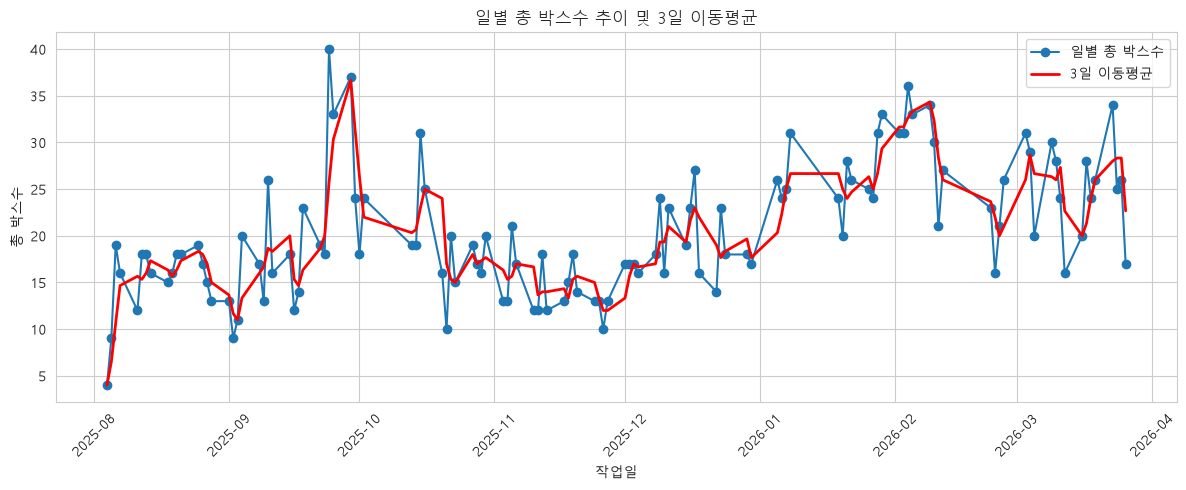

In [34]:
# 그래프 코드

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(12, 5))

plt.plot(daily_boxes['작업일'], daily_boxes['처리 수량(BOX)'], marker='o', label='일별 총 박스수')
plt.plot(daily_boxes['작업일'], daily_boxes['3일이동평균'], color='red', linewidth=2, label='3일 이동평균')

plt.title('일별 총 박스수 추이 및 3일 이동평균')
plt.xlabel('작업일')
plt.ylabel('총 박스수')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()